In [4]:
# ============================================================
# 0. CONFIG AUR IMPORTS - path aur switches yahin se badlein
# ============================================================
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             precision_recall_curve, mean_absolute_error, mean_squared_error, r2_score)
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier, LGBMRegressor, early_stopping
from xgboost import XGBClassifier, XGBRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

DATA_DIR = Path(r"D:\git")
CSV_FILE = DATA_DIR / "olist_merged_full.csv"
OUT_DIR = DATA_DIR / "clv_outputs"
OUT_DIR.mkdir(exist_ok=True)

SPLIT_DATE = pd.Timestamp("2018-03-01")   # is date se pehle ka data = observation window
FEATURE_MODE = "first_order"              # "first_order" (leak-free, tajweez) ya "aggregate" (purana tareeqa)
USE_SMOTE = True                          # True = SMOTE (sirf train par), False = class weights
RUN_OPTUNA = False                        # True = LightGBM Optuna tuning (time lagta hai)
N_TRIALS = 30
QUICK_MODE = False                        # True = RandomForest/KNN skip (jaldi test ke liye)
SEED = 42
print("Config ready | FEATURE_MODE =", FEATURE_MODE, "| USE_SMOTE =", USE_SMOTE)

Config ready | FEATURE_MODE = first_order | USE_SMOTE = True


In [5]:
# ============================================================
# 1. DATA LOADING - merged file read karna aur basic overview
# ============================================================
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
df = pd.read_csv("olist merged full.csv", parse_dates=date_cols)

print("Shape:", df.shape)
print("Date range:", df["order_purchase_timestamp"].min(), "->", df["order_purchase_timestamp"].max())
print("Unique orders:", df["order_id"].nunique(), "| unique customers:", df["customer_unique_id"].nunique())
assert df["order_id"].is_unique, "order_id duplicate hai - merge dobara check karein"
df.info()

Shape: (99441, 38)
Date range: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18
Unique orders: 99441 | unique customers: 96096
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 38 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
 8   customer_unique_id             99441 non-null  str           
 9   customer_zip_code_prefix       99441 no

In [6]:
# ============================================================
# 2. MISSING VALUES ANALYSIS - imputation se pehle ki halat
# ============================================================
miss = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
miss = miss[miss["missing"] > 0].sort_values("missing", ascending=False)
print(miss)
print("Total missing cells:", int(df.isna().sum().sum()))

                               missing    pct
review_comment_title             87888  88.38
review_comment_message           58605  58.93
order_delivered_customer_date     2965   2.98
main_category                     2185   2.20
avg_photos                        2164   2.18
order_delivered_carrier_date      1783   1.79
distance_km                       1266   1.27
seller_lat                         993   1.00
seller_lng                         993   1.00
n_sellers                          775   0.78
n_categories                       775   0.78
n_items                            775   0.78
freight                            775   0.78
seller_zip_code_prefix             775   0.78
total_weight_g                     775   0.78
seller_state                       775   0.78
total_volume_cm3                   775   0.78
price                              775   0.78
seller_id                          775   0.78
review_score                       768   0.77
has_comment                       

In [7]:
# ============================================================
# 3. IMPUTATION - har column ke liye alag method, pehle missing indicators
# ============================================================
# Missing indicators (fill se pehle)
df["is_shipped"] = df["order_delivered_carrier_date"].notna().astype(int)
df["is_delivered"] = df["order_delivered_customer_date"].notna().astype(int)
df["items_missing"] = df["n_items"].isna().astype(int)
df["has_review"] = df["review_score"].notna().astype(int)

# Median gap imputation: approval / carrier / customer dates
gap_approved = (df["order_approved_at"] - df["order_purchase_timestamp"]).median()
gap_carrier = (df["order_delivered_carrier_date"] - df["order_approved_at"]).median()
gap_customer = (df["order_delivered_customer_date"] - df["order_delivered_carrier_date"]).median()
df["order_approved_at"] = df["order_approved_at"].fillna(df["order_purchase_timestamp"] + gap_approved)
df["order_delivered_carrier_date"] = df["order_delivered_carrier_date"].fillna(df["order_approved_at"] + gap_carrier)
df["order_delivered_customer_date"] = df["order_delivered_customer_date"].fillna(df["order_delivered_carrier_date"] + gap_customer)

# State-wise median imputation: latitude / longitude
for col, state in [("customer_lat", "customer_state"), ("customer_lng", "customer_state"),
                   ("seller_lat", "seller_state"), ("seller_lng", "seller_state")]:
    df[col] = df[col].fillna(df.groupby(state)[col].transform("median"))
    df[col] = df[col].fillna(df[col].median())

# Rule-based imputation: payment_value = price + freight
mask = df["payment_value"].isna()
df.loc[mask, "payment_value"] = df.loc[mask, "price"] + df.loc[mask, "freight"]

# Constant imputation (0)
zero_cols = ["n_items", "n_sellers", "n_categories", "price", "freight", "total_weight_g",
             "total_volume_cm3", "n_reviews", "has_comment", "payment_value"]
df[zero_cols] = df[zero_cols].fillna(0)

# Category-wise median imputation: avg_photos
df["avg_photos"] = df["avg_photos"].fillna(df.groupby("main_category")["avg_photos"].transform("median"))
df["avg_photos"] = df["avg_photos"].fillna(df["avg_photos"].median())

# Constant imputation (text)
df["main_category"] = df["main_category"].fillna("unknown")
df["seller_id"] = df["seller_id"].fillna("unknown")
df["seller_zip_code_prefix"] = df["seller_zip_code_prefix"].astype("Int64").astype("string").fillna("unknown")
df["seller_state"] = df["seller_state"].fillna("unknown")
df["payment_type"] = df["payment_type"].fillna("not_defined")
df["review_comment_title"] = df["review_comment_title"].fillna("no_comment")
df["review_comment_message"] = df["review_comment_message"].fillna("no_comment")

# Mode imputation
for col in ["installments", "n_payment_methods"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# Median imputation: review_score
df["review_score"] = df["review_score"].fillna(df["review_score"].median())

# Recompute distance_km (haversine)
lat1, lng1, lat2, lng2 = map(np.radians, [df["customer_lat"], df["customer_lng"], df["seller_lat"], df["seller_lng"]])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

for col in ["n_items", "n_sellers", "n_categories", "installments", "n_payment_methods", "n_reviews", "has_comment"]:
    df[col] = df[col].round().astype(int)

print("Remaining missing values:", int(df.isna().sum().sum()), "| shape:", df.shape)

Remaining missing values: 0 | shape: (99441, 42)


In [8]:
# ============================================================
# 4. DUPLICATES - exact, order_id aur same-checkout (split orders, error nahi)
# ============================================================
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate order_id:", df.duplicated(subset=["order_id"]).sum())
df["same_checkout"] = df.duplicated(subset=["customer_unique_id", "order_purchase_timestamp"], keep=False).astype(int)
print("Same-checkout rows (alag sellers, ek hi checkout):", int(df["same_checkout"].sum()))

Exact duplicate rows: 0
Duplicate order_id: 0
Same-checkout rows (alag sellers, ek hi checkout): 582


In [9]:
# ============================================================
# 5. DERIVED FEATURES - delivery, time aur grouping columns
# ============================================================
df["delivery_days"] = ((df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400).where(df["is_delivered"] == 1)
df["delay_days"] = ((df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.total_seconds() / 86400).where(df["is_delivered"] == 1)
df["is_late"] = (df["delay_days"] > 0).astype(int)
df["approval_gap_hours"] = (df["order_approved_at"] - df["order_purchase_timestamp"]).dt.total_seconds() / 3600

df["purchase_hour"] = df["order_purchase_timestamp"].dt.hour
df["purchase_dow"] = df["order_purchase_timestamp"].dt.dayofweek
df["purchase_month"] = df["order_purchase_timestamp"].dt.month
df["is_weekend"] = df["purchase_dow"].isin([5, 6]).astype(int)

msg = df["review_comment_message"].astype("string")
df["comment_len"] = msg.where(msg != "no_comment", "").str.len().fillna(0).astype(int)

top_cat = df["main_category"].value_counts().head(10).index
df["cat_grouped"] = df["main_category"].where(df["main_category"].isin(top_cat), "other")
top_states = df["customer_state"].value_counts().head(5).index
df["state_grouped"] = df["customer_state"].where(df["customer_state"].isin(top_states), "other")
print(df[["delivery_days", "delay_days", "is_late", "approval_gap_hours", "comment_len"]].describe().T.round(2))

                      count   mean    std     min    25%    50%    75%      max
delivery_days       96476.0  12.56   9.55    0.53   6.77  10.22  15.72   209.63
delay_days          96476.0 -11.18  10.19 -146.02 -16.24 -11.95  -6.39   188.98
is_late             99441.0   0.08   0.27    0.00   0.00   0.00   0.00     1.00
approval_gap_hours  99441.0  10.40  26.02    0.00   0.22   0.34  14.54  4509.18
comment_len         99441.0  28.19  48.27    0.00   0.00   0.00  41.00   208.00


In [10]:
# ============================================================
# 6. OUTLIERS - IQR / MAD / Isolation Forest se detect, capping se handle (rows delete nahi)
# ============================================================
cont_cols = ["price", "freight", "payment_value", "total_weight_g", "total_volume_cm3",
             "distance_km", "delivery_days", "delay_days", "approval_gap_hours"]
rows = []
for c in cont_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((s < lo) | (s > hi)).sum())
    mad = np.median(np.abs(s - s.median()))
    n_mad = int(((0.6745 * (s - s.median()) / mad).abs() > 3.5).sum()) if mad > 0 else None
    rows.append({"column": c, "min": round(s.min(), 2), "max": round(s.max(), 2),
                 "IQR_outliers": n_iqr, "IQR_pct": round(n_iqr / len(s) * 100, 2), "MAD_outliers": n_mad})
print(pd.DataFrame(rows).to_string(index=False))

Xo = np.log1p(df[cont_cols].clip(lower=0))
Xo = Xo.fillna(Xo.median())
iso_flag = IsolationForest(contamination=0.01, random_state=SEED, n_jobs=-1).fit_predict(Xo) == -1
df["iso_outlier"] = iso_flag.astype(int)
print("Isolation Forest outliers:", int(df["iso_outlier"].sum()))

# Winsorization (1st-99th percentile): original column safe, naya _capped column
cap_cols = ["price", "freight", "payment_value", "total_weight_g", "total_volume_cm3", "distance_km"]
for c in cap_cols:
    df[c + "_capped"] = df[c].clip(df[c].quantile(0.01), df[c].quantile(0.99))
df["freight_ratio"] = df["freight_capped"] / df["price_capped"].replace(0, np.nan)
df["freight_ratio"] = df["freight_ratio"].fillna(df["freight_ratio"].median())
print({c: (round(df[c].max(), 1), round(df[c + "_capped"].max(), 1)) for c in cap_cols})

            column     min        max  IQR_outliers  IQR_pct  MAD_outliers
             price    0.00   13440.00          7903     7.95          7277
           freight    0.00    1794.96          9992    10.05          9705
     payment_value    0.00   13664.08          7866     7.91          6908
    total_weight_g    0.00  184400.00         13870    13.95         16609
  total_volume_cm3    0.00 1476000.00          9165     9.22         13273
       distance_km    0.00    8677.91          7677     7.72          5981
     delivery_days    0.53     209.63          4899     5.08          3863
        delay_days -146.02     188.98          4875     5.05          2465
approval_gap_hours    0.00    4509.18          9213     9.26         33969
Isolation Forest outliers: 995
{'price': (np.float64(13440.0), np.float64(998.0)), 'freight': (np.float64(1795.0), np.float64(104.7)), 'payment_value': (np.float64(13664.1), np.float64(1075.8)), 'total_weight_g': (np.float64(184400.0), np.float64(223

                         count     mean      std    min     25%     50%      75%       max
price_capped           99441.0   130.82   155.69   7.90   45.00   85.00   149.90    998.00
freight_capped         99441.0    22.08    16.38   0.00   13.72   17.09    23.92    104.73
payment_value_capped   99441.0   154.85   166.57  22.38   62.01  105.29   176.97   1075.79
delivery_days          96476.0    12.56     9.55   0.53    6.77   10.22    15.72    209.63
distance_km_capped     99441.0   598.68   584.82   5.77  183.78  433.93   800.24   2483.10
total_weight_g_capped  99441.0  2267.02  3898.29  50.00  300.00  738.00  2050.00  22350.00
review_score           99441.0     4.09     1.34   1.00    4.00    5.00     5.00      5.00
installments           99441.0     2.93     2.72   0.00    1.00    2.00     4.00     24.00


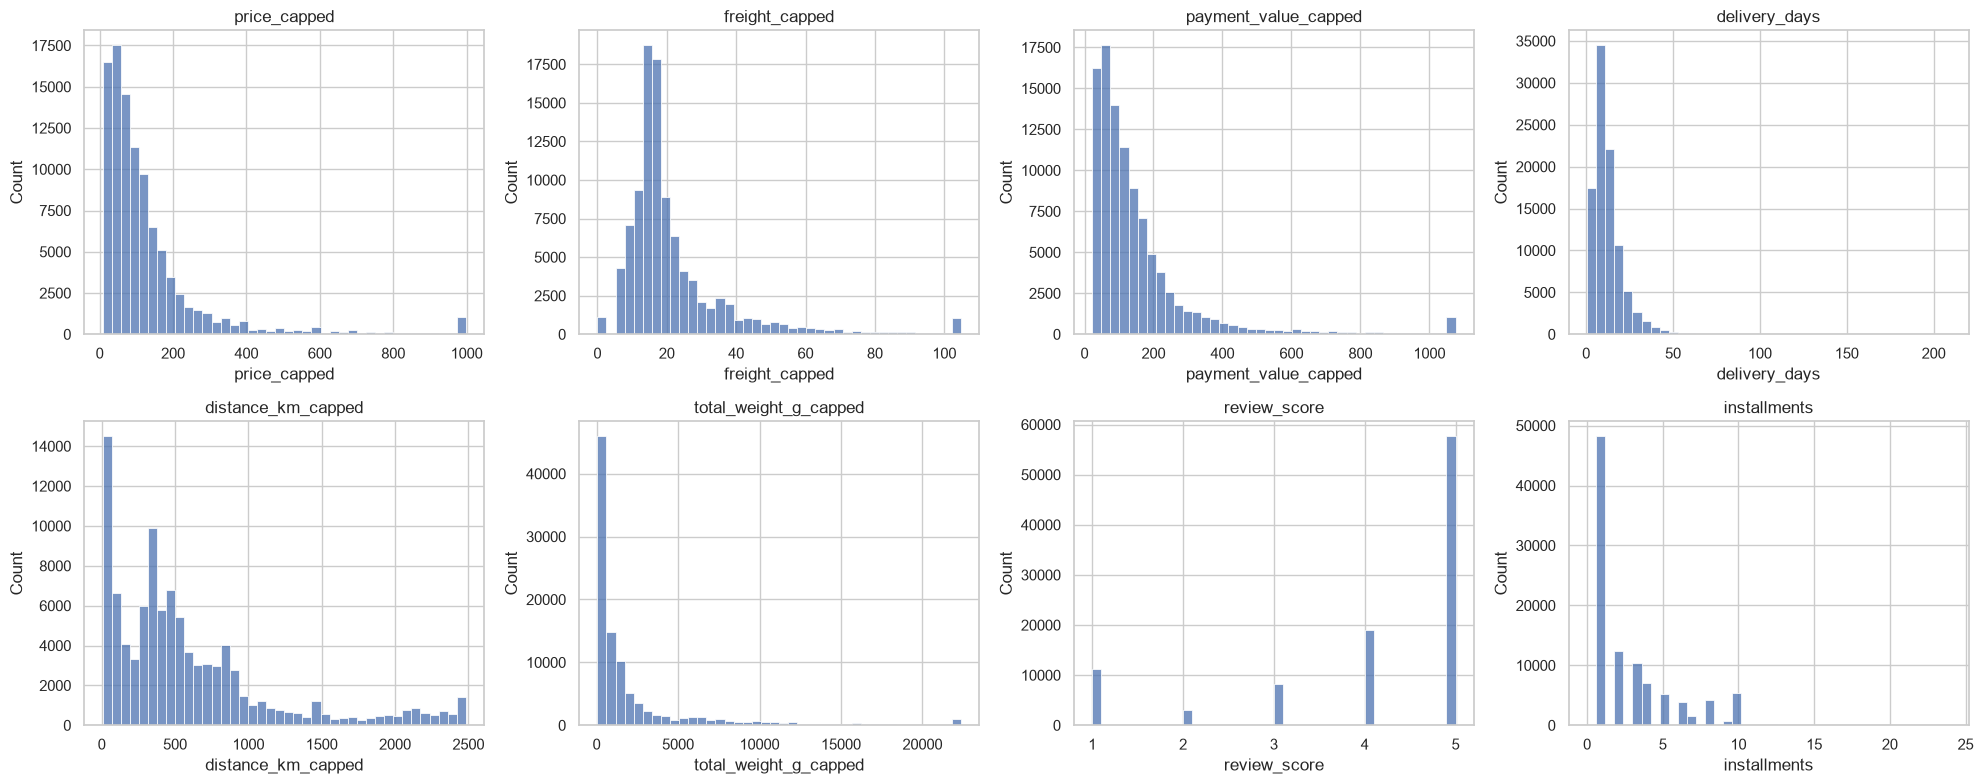

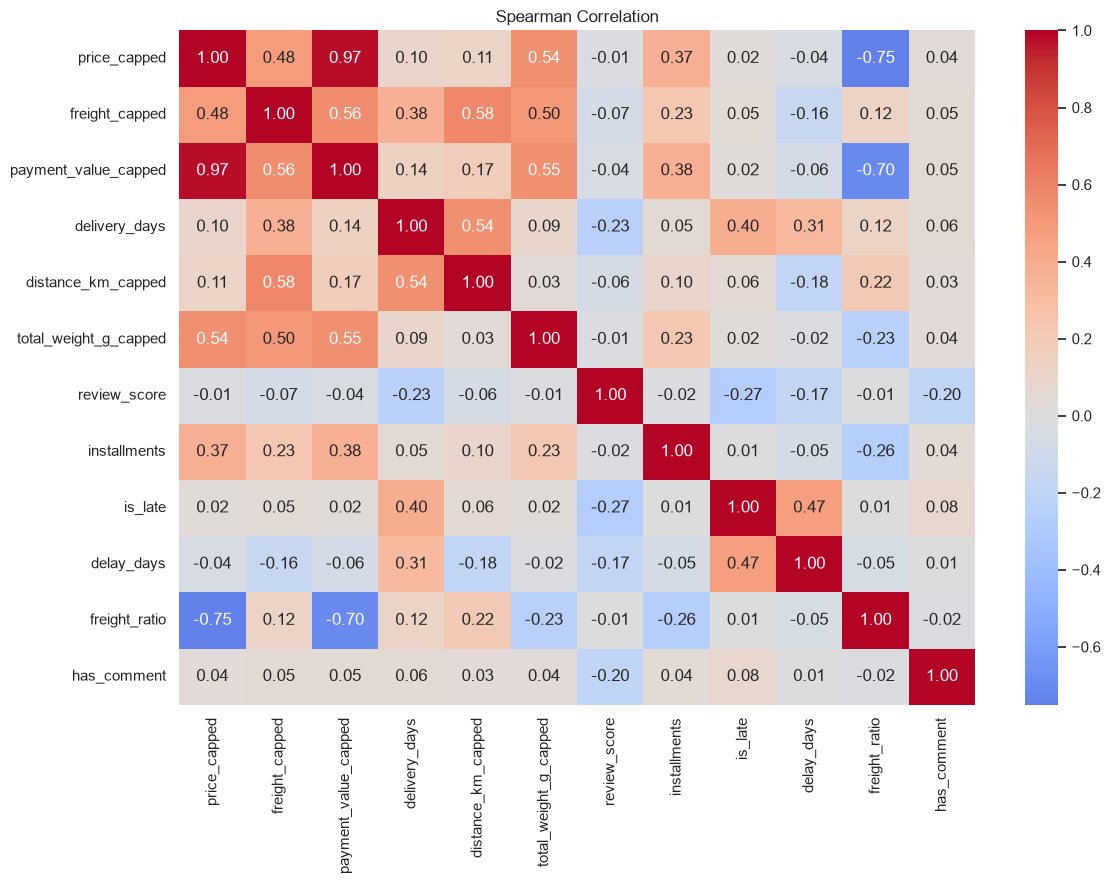

Skewness / Kurtosis:
                       skew   kurt
price_capped           3.28  12.93
freight_capped         2.69   8.77
payment_value_capped   3.22  12.52
delivery_days          3.83  39.31
distance_km_capped     1.57   2.05
total_weight_g_capped  3.07  10.23
review_score          -1.38   0.54
installments           1.60   2.35
Late delivery rate: 8.11% | review (late) 2.62 vs (on-time) 4.30
              feature   VIF
0        price_capped  1.42
1      freight_capped  1.50
2        installments  1.17
3       delivery_days  1.32
4        review_score  1.13
5  distance_km_capped  1.37


In [11]:
# ============================================================
# 7. EDA - descriptive stats, distribution, correlation, skewness, VIF
# ============================================================
eda_num = ["price_capped", "freight_capped", "payment_value_capped", "delivery_days", "distance_km_capped",
           "total_weight_g_capped", "review_score", "installments"]
print(df[eda_num].describe().T.round(2))

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), eda_num):
    sns.histplot(df[c].dropna(), bins=40, ax=ax).set_title(c)
plt.tight_layout()
plt.show()

corr_cols = eda_num + ["is_late", "delay_days", "freight_ratio", "has_comment"]
plt.figure(figsize=(12, 9))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman Correlation")
plt.tight_layout()
plt.show()

print("Skewness / Kurtosis:")
print(pd.DataFrame({"skew": df[eda_num].skew(), "kurt": df[eda_num].kurt()}).round(2))

deliv = df[df["is_delivered"] == 1]
print("Late delivery rate: %.2f%% | review (late) %.2f vs (on-time) %.2f" % (
    deliv["is_late"].mean() * 100, deliv.loc[deliv.is_late == 1, "review_score"].mean(),
    deliv.loc[deliv.is_late == 0, "review_score"].mean()))

vif_in = deliv[["price_capped", "freight_capped", "installments", "delivery_days", "review_score", "distance_km_capped"]].dropna().sample(20000, random_state=SEED).assign(const=1.0)
print(pd.DataFrame({"feature": vif_in.columns[:-1],
                    "VIF": [variance_inflation_factor(vif_in.values, i) for i in range(vif_in.shape[1] - 1)]}).round(2))

In [12]:
# ============================================================
# 8. CUSTOMER TABLE - observation window (SPLIT_DATE se pehle), features aur targets
# ============================================================
valid = df[(df["order_status"] != "canceled") & (df["order_purchase_timestamp"] < SPLIT_DATE)]
valid = valid.sort_values(["order_purchase_timestamp", "order_id"])
snapshot = valid["order_purchase_timestamp"].max()

base = valid.groupby("customer_unique_id").agg(
    frequency=("order_purchase_timestamp", "nunique"),
    monetary=("payment_value_capped", "sum"),
    first_purchase=("order_purchase_timestamp", "min"),
    last_purchase=("order_purchase_timestamp", "max")).reset_index()
base["is_repeat"] = (base["frequency"] > 1).astype(int)

if FEATURE_MODE == "first_order":
    first = valid.drop_duplicates("customer_unique_id", keep="first").set_index("customer_unique_id")
    feats = pd.DataFrame({
        "f_order_value": first["payment_value_capped"], "f_price": first["price_capped"],
        "f_freight_ratio": first["freight_ratio"], "f_delivery_days": first["delivery_days"],
        "f_is_late": first["is_late"], "f_review": first["review_score"],
        "f_has_comment": first["has_comment"], "f_comment_len": first["comment_len"],
        "f_installments": first["installments"], "f_n_items": first["n_items"],
        "f_n_categories": first["n_categories"], "f_distance_km": first["distance_km_capped"],
        "f_weight_g": first["total_weight_g_capped"], "f_photos": first["avg_photos"],
        "f_is_weekend": first["is_weekend"], "f_hour": first["purchase_hour"]})
    feats["f_delivery_days"] = feats["f_delivery_days"].fillna(feats["f_delivery_days"].median())
    cats = first[["state_grouped", "payment_type", "cat_grouped"]]
    feats = feats.reset_index()
    cats = cats.reset_index()
    cust = base.merge(feats, on="customer_unique_id").merge(cats, on="customer_unique_id")
    cust["days_since_first_order"] = (snapshot - cust["first_purchase"]).dt.days
    num_features = [c for c in feats.columns if c != "customer_unique_id"] + ["days_since_first_order"]
else:
    agg = valid.groupby("customer_unique_id").agg(
        avg_order_value=("payment_value_capped", "mean"), avg_price=("price_capped", "mean"),
        avg_freight_ratio=("freight_ratio", "mean"), avg_delivery_days=("delivery_days", "mean"),
        late_rate=("is_late", "mean"), avg_review=("review_score", "mean"),
        n_categories=("cat_grouped", "nunique"), weekend_rate=("is_weekend", "mean"),
        state_grouped=("state_grouped", lambda x: x.mode()[0]),
        payment_type=("payment_type", lambda x: x.mode()[0])).reset_index()
    agg["avg_delivery_days"] = agg["avg_delivery_days"].fillna(agg["avg_delivery_days"].median())
    cust = base.merge(agg, on="customer_unique_id")
    cust["recency_days"] = (snapshot - cust["last_purchase"]).dt.days
    num_features = ["avg_order_value", "avg_price", "avg_freight_ratio", "avg_delivery_days", "late_rate",
                    "avg_review", "n_categories", "weekend_rate", "recency_days"]
    cat_cols_use = ["state_grouped", "payment_type"]

cat_cols_use = [c for c in ["state_grouped", "payment_type", "cat_grouped"] if c in cust.columns]
dummies = pd.get_dummies(cust[cat_cols_use], drop_first=True).astype(int)
X = pd.concat([cust[num_features], dummies], axis=1)
y_class = cust["is_repeat"]
y_reg = cust["monetary"]
print("Mode:", FEATURE_MODE, "| customers:", len(cust), "| features:", X.shape[1])
print(X.columns.tolist())

Mode: first_order | customers: 57143 | features: 36
['f_order_value', 'f_price', 'f_freight_ratio', 'f_delivery_days', 'f_is_late', 'f_review', 'f_has_comment', 'f_comment_len', 'f_installments', 'f_n_items', 'f_n_categories', 'f_distance_km', 'f_weight_g', 'f_photos', 'f_is_weekend', 'f_hour', 'days_since_first_order', 'state_grouped_PR', 'state_grouped_RJ', 'state_grouped_RS', 'state_grouped_SP', 'state_grouped_other', 'payment_type_credit_card', 'payment_type_debit_card', 'payment_type_not_defined', 'payment_type_voucher', 'cat_grouped_bed_bath_table', 'cat_grouped_computers_accessories', 'cat_grouped_furniture_decor', 'cat_grouped_health_beauty', 'cat_grouped_housewares', 'cat_grouped_other', 'cat_grouped_sports_leisure', 'cat_grouped_telephony', 'cat_grouped_toys', 'cat_grouped_watches_gifts']


is_repeat
0    55622
1     1521
Name: count, dtype: int64
is_repeat
0    97.34
1     2.66
Name: proportion, dtype: float64
Imbalance ratio (one-time : repeat) = 36.6 : 1


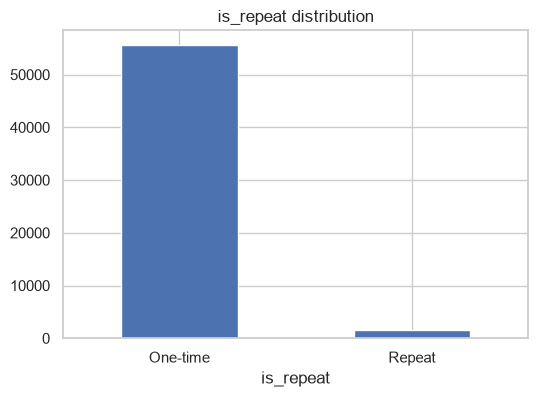

           count    mean  median
is_repeat                       
0          55622  153.76  104.56
1           1521  299.16  220.33


In [13]:
# ============================================================
# 9. TARGET ANALYSIS - is_repeat distribution aur class imbalance
# ============================================================
vc = y_class.value_counts()
print(vc)
print((y_class.value_counts(normalize=True) * 100).round(2))
print("Imbalance ratio (one-time : repeat) = %.1f : 1" % (vc[0] / vc[1]))
vc.sort_index().plot(kind="bar", figsize=(6, 4), title="is_repeat distribution")
plt.xticks([0, 1], ["One-time", "Repeat"], rotation=0)
plt.show()
print(cust.groupby("is_repeat")["monetary"].agg(["count", "mean", "median"]).round(2))

In [14]:
# ============================================================
# 10. LEAKAGE CHECK - target se seedha judi columns X me nahi honi chahiye
# ============================================================
banned = ["frequency", "monetary", "tenure_days", "first_purchase", "last_purchase", "customer_unique_id", "is_repeat"]
assert not [c for c in banned if c in X.columns], "X me leak wali column maujood hai"

spear = X.apply(lambda s: stats.spearmanr(s, y_class)[0]).abs().sort_values(ascending=False)
print("Top 8 features by |Spearman| with is_repeat:")
print(spear.head(8).round(3))
if spear.iloc[0] > 0.5:
    print("WARNING: bohat strong feature mili - leakage dobara check karein")
else:
    print("OK: koi feature target ki near-perfect proxy nahi.")

Top 8 features by |Spearman| with is_repeat:
days_since_first_order         0.059
cat_grouped_bed_bath_table     0.031
f_installments                 0.026
f_photos                       0.020
f_n_items                      0.018
cat_grouped_other              0.017
cat_grouped_furniture_decor    0.017
f_freight_ratio                0.016
dtype: float64
OK: koi feature target ki near-perfect proxy nahi.


In [15]:
# ============================================================
# 11. SPLIT -> SCALE -> SMOTE (SMOTE sirf training part par, test/validation asli rehte hain)
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2, stratify=y_class, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

X_fit, X_val, y_fit, y_val = train_test_split(X_train_s, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
PRIOR = float(y_train.mean())

if USE_SMOTE:
    X_bal, y_bal = SMOTE(random_state=SEED).fit_resample(X_fit, y_fit)
    cw, spw = None, 1.0
else:
    X_bal, y_bal = X_fit, y_fit
    cw, spw = "balanced", float((y_fit == 0).sum() / (y_fit == 1).sum())

print("Train (real):", y_fit.value_counts().to_dict(), "| Train (used):", y_bal.value_counts().to_dict())
print("Validation:", y_val.value_counts().to_dict(), "| Test:", y_test.value_counts().to_dict())

Train (real): {0: 37822, 1: 1034} | Train (used): {0: 37822, 1: 37822}
Validation: {0: 6675, 1: 183} | Test: {0: 11125, 1: 304}


In [16]:
# ============================================================
# 12. MODEL COMPARISON - 7 classifiers, selection validation AUC par, result test par
# ============================================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight=cw, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, class_weight=cw, random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, class_weight=cw, random_state=SEED, verbose=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, scale_pos_weight=spw, eval_metric="logloss", random_state=SEED),
}
if not QUICK_MODE:
    models["Random Forest"] = RandomForestClassifier(n_estimators=200, class_weight=cw, n_jobs=-1, random_state=SEED)
    models["KNN"] = KNeighborsClassifier(n_neighbors=15)

def clf_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"roc_auc": roc_auc_score(y_true, proba), "pr_auc": average_precision_score(y_true, proba),
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred)}

rows = []
for name, m in models.items():
    m.fit(X_bal, y_bal)
    pv, pt = m.predict_proba(X_val)[:, 1], m.predict_proba(X_test_s)[:, 1]
    r = {"model": name, "val_auc": roc_auc_score(y_val, pv)}
    r.update({"test_" + k: v for k, v in clf_metrics(y_test, pt).items()})
    rows.append(r)
    print(f"{name}: val AUC {r['val_auc']:.4f} | test AUC {r['test_roc_auc']:.4f}")

results = pd.DataFrame(rows).sort_values("val_auc", ascending=False).round(4)
print(results.to_string(index=False))
best_name = results.iloc[0]["model"]
print("Best model (validation AUC):", best_name)

Logistic Regression: val AUC 0.6264 | test AUC 0.6088
Decision Tree: val AUC 0.5775 | test AUC 0.5764
Naive Bayes: val AUC 0.5837 | test AUC 0.5455
LightGBM: val AUC 0.6475 | test AUC 0.5960
XGBoost: val AUC 0.6622 | test AUC 0.5908
Random Forest: val AUC 0.6456 | test AUC 0.6091
KNN: val AUC 0.5403 | test AUC 0.5595
              model  val_auc  test_roc_auc  test_pr_auc  test_precision  test_recall  test_f1
            XGBoost   0.6622        0.5908       0.0518          0.4444       0.0132   0.0256
           LightGBM   0.6475        0.5960       0.0543          0.4286       0.0099   0.0193
      Random Forest   0.6456        0.6091       0.0430          0.1200       0.0099   0.0182
Logistic Regression   0.6264        0.6088       0.0380          0.0388       0.5691   0.0727
        Naive Bayes   0.5837        0.5455       0.0313          0.0267       0.9079   0.0519
      Decision Tree   0.5775        0.5764       0.0402          0.0405       0.2434   0.0695
                KNN   0

In [17]:
# ============================================================
# 13. FINAL CLASSIFIER - LightGBM (Optuna optional) + early stopping, validation asli (SMOTE-free)
# ============================================================
best_params = dict(n_estimators=600, learning_rate=0.05, num_leaves=31, max_depth=8, min_child_samples=50,
                   colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0)

if RUN_OPTUNA:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective(trial):
        p = {"n_estimators": 800, "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
             "num_leaves": trial.suggest_int("num_leaves", 15, 120), "max_depth": trial.suggest_int("max_depth", 3, 10),
             "min_child_samples": trial.suggest_int("min_child_samples", 10, 150),
             "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
             "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
             "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)}
        m = LGBMClassifier(**p, class_weight=cw, random_state=SEED, verbose=-1)
        m.fit(X_bal, y_bal, eval_set=[(X_val, y_val)], eval_metric="auc", callbacks=[early_stopping(50, verbose=False)])
        return roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=N_TRIALS)
    best_params = {**study.best_params, "n_estimators": 800}
    print("Optuna best val AUC:", round(study.best_value, 4), best_params)

final_clf = LGBMClassifier(**best_params, class_weight=cw, random_state=SEED, verbose=-1)
final_clf.fit(X_bal, y_bal, eval_set=[(X_val, y_val)], eval_metric="auc", callbacks=[early_stopping(50, verbose=False)])
print("Best iteration:", final_clf.best_iteration_)

def adjust(p):
    return p * PRIOR / (p * PRIOR + (1 - p) * (1 - PRIOR)) if USE_SMOTE else p

pv = final_clf.predict_proba(X_val)[:, 1]
pt = final_clf.predict_proba(X_test_s)[:, 1]
print("Validation AUC: %.4f | Test AUC: %.4f (gap chhota hona chahiye)" % (roc_auc_score(y_val, pv), roc_auc_score(y_test, pt)))

Best iteration: 109
Validation AUC: 0.6608 | Test AUC: 0.5822 (gap chhota hona chahiye)


Best threshold (validation F1): 0.215
default 0.5 {'roc_auc': 0.5822, 'pr_auc': 0.0472, 'precision': 0.18, 'recall': 0.0296, 'f1': 0.0508}
tuned {'roc_auc': 0.5822, 'pr_auc': 0.0472, 'precision': 0.0415, 'recall': 0.1974, 'f1': 0.0685}


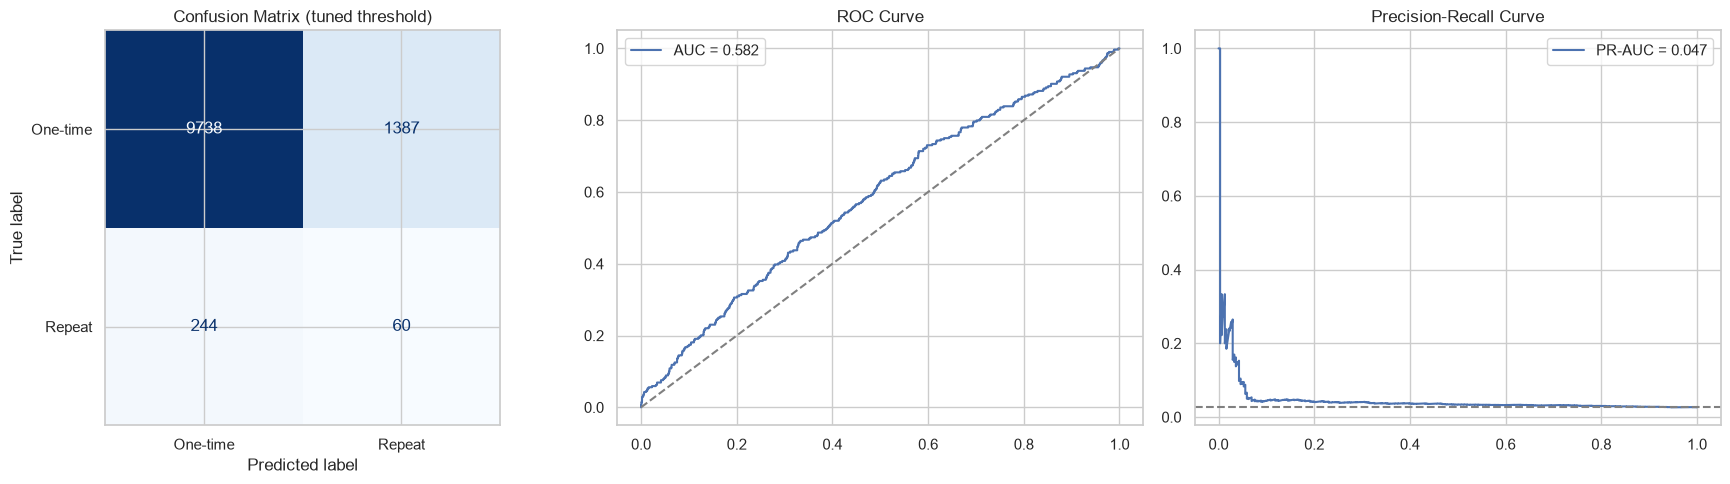

Decile lift (decile 1 = sab se zyada probability):
        sum   mean   lift
decile                   
1        52  0.045  1.710
2        41  0.036  1.349
3        31  0.027  1.020
4        31  0.027  1.020
5        34  0.030  1.118
6        31  0.027  1.021
7        22  0.019  0.724
8        21  0.018  0.691
9        19  0.017  0.625
10       22  0.019  0.724


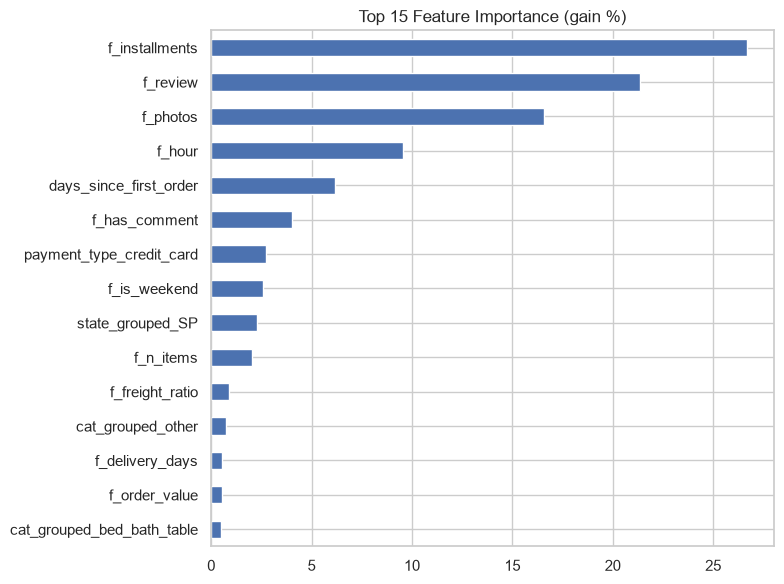

f_installments              26.70
f_review                    21.34
f_photos                    16.58
f_hour                       9.54
days_since_first_order       6.16
f_has_comment                4.04
payment_type_credit_card     2.72
f_is_weekend                 2.57
state_grouped_SP             2.29
f_n_items                    2.04
dtype: float64


In [18]:
# ============================================================
# 14. THRESHOLD TUNING aur FINAL EVALUATION - confusion matrix, ROC, PR, lift
# ============================================================
prec, rec, thr = precision_recall_curve(y_val, pv)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
best_thr = float(thr[np.argmax(f1s[:-1])])
print("Best threshold (validation F1): %.3f" % best_thr)

for label, t in [("default 0.5", 0.5), ("tuned", best_thr)]:
    print(label, {k: round(v, 4) for k, v in clf_metrics(y_test, pt, t).items()})

pred_t = (pt >= best_thr).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_t), display_labels=["One-time", "Repeat"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix (tuned threshold)")
fpr, tpr, _ = roc_curve(y_test, pt)
axes[1].plot(fpr, tpr, label="AUC = %.3f" % roc_auc_score(y_test, pt))
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("ROC Curve")
axes[1].legend()
p_, r_, _ = precision_recall_curve(y_test, pt)
axes[2].plot(r_, p_, label="PR-AUC = %.3f" % average_precision_score(y_test, pt))
axes[2].axhline(y_test.mean(), ls="--", color="gray")
axes[2].set_title("Precision-Recall Curve")
axes[2].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "classifier_evaluation.png")
plt.show()

order = np.argsort(-pt)
decile = pd.DataFrame({"y": y_test.values[order]})
decile["decile"] = pd.qcut(np.arange(len(decile)), 10, labels=range(1, 11))
lift = decile.groupby("decile")["y"].agg(["sum", "mean"])
lift["lift"] = lift["mean"] / y_test.mean()
print("Decile lift (decile 1 = sab se zyada probability):")
print(lift.round(3))

imp = pd.Series(final_clf.booster_.feature_importance("gain"), index=X.columns)
imp = (imp / imp.sum() * 100).sort_values(ascending=False)
imp.head(15)[::-1].plot(kind="barh", figsize=(8, 6), title="Top 15 Feature Importance (gain %)")
plt.tight_layout()
plt.savefig(OUT_DIR / "feature_importance.png")
plt.show()
print(imp.head(10).round(2))

In [19]:
# ============================================================
# 15. SPEND MODEL - sirf repeat customers par 7 regressors compare
# ============================================================
rep_tr = y_train[y_train == 1].index
rep_te = y_test[y_test == 1].index
scaler_reg = StandardScaler().fit(X.loc[rep_tr])
Xr_tr, Xr_te = scaler_reg.transform(X.loc[rep_tr]), scaler_reg.transform(X.loc[rep_te])
yr_tr, yr_te = y_reg.loc[rep_tr], y_reg.loc[rep_te]

regs = {"Linear Regression": LinearRegression(), "Ridge": Ridge(alpha=1.0), "Lasso": Lasso(alpha=0.01),
        "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.5),
        "XGBoost": XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=SEED),
        "LightGBM": LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1)}
if not QUICK_MODE:
    regs["Random Forest"] = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED)

rrows = []
for name, m in regs.items():
    m.fit(Xr_tr, np.log1p(yr_tr))
    p = np.expm1(m.predict(Xr_te))
    rrows.append({"model": name, "mae": mean_absolute_error(yr_te, p), "rmse": mean_squared_error(yr_te, p) ** 0.5, "r2": r2_score(yr_te, p)})
reg_results = pd.DataFrame(rrows).sort_values("rmse").round(3)
print(reg_results.to_string(index=False))
print("Mean-baseline RMSE:", round(mean_squared_error(yr_te, np.full(len(yr_te), yr_tr.mean())) ** 0.5, 2))
best_reg = regs[reg_results.iloc[0]["model"]]
print("Best regressor:", reg_results.iloc[0]["model"])

            model     mae    rmse     r2
    Random Forest 100.182 180.320  0.574
         LightGBM 100.314 181.956  0.566
          XGBoost 106.359 190.457  0.524
            Lasso 121.949 277.615 -0.011
       ElasticNet 123.874 286.750 -0.079
Linear Regression 126.783 296.979 -0.157
            Ridge 126.607 297.268 -0.159
Mean-baseline RMSE: 276.3
Best regressor: Random Forest


In [20]:
# ============================================================
# 16. CLV SCORE = P(repeat) x Predicted spend, phir segments (Platinum/Gold/Silver/Bronze)
# ============================================================
X_all_s = pd.DataFrame(scaler.transform(X), columns=X.columns, index=X.index)
p_repeat = adjust(final_clf.predict_proba(X_all_s)[:, 1])
spend_pred = np.clip(np.expm1(best_reg.predict(scaler_reg.transform(X))), 0, None)

scored = cust[["customer_unique_id", "frequency", "monetary", "is_repeat"]].copy()
scored["p_repeat"] = p_repeat.round(4)
scored["predicted_spend"] = spend_pred.round(2)
scored["clv_score"] = (p_repeat * spend_pred).round(3)
q = scored["clv_score"].rank(pct=True)
scored["segment"] = np.select([q > 0.95, q > 0.80, q > 0.50], ["Platinum", "Gold", "Silver"], "Bronze")
scored["split"] = np.where(cust.index.isin(X_train.index), "train", "test")

print(scored.groupby("segment").agg(customers=("segment", "size"), repeat_rate=("is_repeat", "mean"),
                                    avg_p=("p_repeat", "mean"), avg_spend=("predicted_spend", "mean")).round(3))
scored.to_csv(OUT_DIR / "clv_scored_customers.csv", index=False)
print("Saved:", OUT_DIR / "clv_scored_customers.csv")

          customers  repeat_rate  avg_p  avg_spend
segment                                           
Bronze        28585        0.017  0.002    208.366
Gold           8565        0.043  0.007    437.242
Platinum       2856        0.074  0.014    593.536
Silver        17137        0.026  0.004    318.605
Saved: D:\git\clv_outputs\clv_scored_customers.csv


In [21]:
# ============================================================
# 17. FINAL INSIGHTS - poore project ka summary
# ============================================================
top10 = cust["monetary"].sort_values(ascending=False).head(int(len(cust) * 0.1)).sum() / cust["monetary"].sum() * 100
tm = clf_metrics(y_test, pt, best_thr)
print("=" * 70)
print("FINAL INSIGHTS - OLIST CLV PREDICTION")
print("=" * 70)
print(f"1. Data: {len(df):,} orders, {df['customer_unique_id'].nunique():,} customers; model {len(cust):,} customers (before {SPLIT_DATE.date()}).")
print(f"2. Repeat rate {y_class.mean() * 100:.2f}% (imbalance {vc[0] / vc[1]:.1f}:1) -> SMOTE sirf train par: {USE_SMOTE}.")
print(f"3. Top 10% customers = {top10:.1f}% revenue.")
print(f"4. Late delivery rate {deliv['is_late'].mean() * 100:.1f}%, late orders ka review {deliv.loc[deliv.is_late == 1, 'review_score'].mean():.2f} vs {deliv.loc[deliv.is_late == 0, 'review_score'].mean():.2f}.")
print(f"5. Feature mode: {FEATURE_MODE}. Best classifier: LightGBM -> Test ROC-AUC {tm['roc_auc']:.3f}, PR-AUC {tm['pr_auc']:.3f}, recall {tm['recall']:.2f}, precision {tm['precision']:.2f}.")
print(f"6. Best spend model: {reg_results.iloc[0]['model']} (R2 {reg_results.iloc[0]['r2']:.2f}, MAE {reg_results.iloc[0]['mae']:.1f}).")
print(f"7. Top drivers: {', '.join(imp.head(5).index)}.")
print("8. Leakage: frequency/tenure_days/monetary X se bahar, SMOTE split ke baad, validation/test asli.")

FINAL INSIGHTS - OLIST CLV PREDICTION
1. Data: 99,441 orders, 96,096 customers; model 57,143 customers (before 2018-03-01).
2. Repeat rate 2.66% (imbalance 36.6:1) -> SMOTE sirf train par: True.
3. Top 10% customers = 35.9% revenue.
4. Late delivery rate 8.1%, late orders ka review 2.62 vs 4.30.
5. Feature mode: first_order. Best classifier: LightGBM -> Test ROC-AUC 0.582, PR-AUC 0.047, recall 0.20, precision 0.04.
6. Best spend model: Random Forest (R2 0.57, MAE 100.2).
7. Top drivers: f_installments, f_review, f_photos, f_hour, days_since_first_order.
8. Leakage: frequency/tenure_days/monetary X se bahar, SMOTE split ke baad, validation/test asli.


In [7]:
df.shape

(99441, 38)